In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import random
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

In [5]:
random.seed(42)
np.random.seed(42)
TARGET_SIZE = (45, 45)

Сгенерирована строка: '16y90*x0(596'


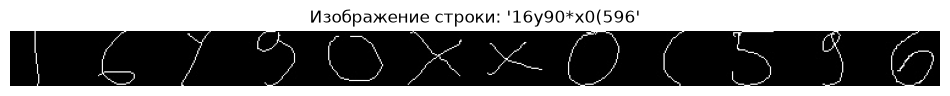

In [16]:
class SymbolGenerator:
    def __init__(self, data_path, available_gen_percent=0.8):
        self.data_path = data_path
        self.available_gen_percent = available_gen_percent
        self.available_symbols = list(('(', ')', '0', '1', '2', '3', '4', '5', '6',
                                       '7', '8', '9', 't', 'x', 'y', ',', '+', '-', '*', ' '))

    def get_random_symbol_image(self, char):
        if char == ' ':
            return np.ones((40, 40), dtype=np.uint8) * 255
        folder_name = {'x': 'X', '*': 'times'}.get(char, char)
        symbol_dir = os.path.join(self.data_path, folder_name)
        images = sorted(os.listdir(symbol_dir))
        start = int(len(images) * self.available_gen_percent)
        path = os.path.join(symbol_dir, random.choice(images[start:]))
        return cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    def generate_sequence(self, length=10):
        sequence = ''.join(random.choices(self.available_symbols, k=length))
        images = [self.get_random_symbol_image(c) for c in sequence]
        return sequence, [img for img in images if img is not None]


def gen_image_line(images, spacing=20):
    t_width = sum(img.shape[1] for img in images) + spacing * (len(images) - 1)
    m_height = max(img.shape[0] for img in images)
    line = np.ones((m_height, t_width), dtype=np.uint8) * 255
    x = 0
    for img in images:
        h, w = img.shape
        line[m_height - h:m_height, x:x + w] = img
        x += w + spacing
    return cv2.bitwise_not(line)


generator = SymbolGenerator('./data/', 0.8)
seq, imgs = generator.generate_sequence(length=12)
line = gen_image_line(imgs)
print(f"Сгенерирована строка: '{seq}'")

plt.figure(figsize=(12, 2))
plt.title(f"Изображение строки: '{seq}'")
plt.imshow(line, cmap='gray')
plt.axis('off')
plt.show()

In [17]:
def pad_and_crop(img, target_size=TARGET_SIZE, threshold=10):
    h, w = img.shape
    th, tw = target_size
    if h > th or w > tw:
        rows = np.where(np.max(img, axis=1) > threshold)[0]
        cols = np.where(np.max(img, axis=0) > threshold)[0]
        if len(rows) > 0 and len(cols) > 0:
            img = img[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]
        h, w = img.shape
        scale = min(th / h, tw / w)
        if scale < 1.0:
            img = cv2.resize(img, (int(w * scale), int(h * scale)))
    padded = np.zeros(target_size, dtype=np.uint8)
    y0 = (th - img.shape[0]) // 2
    x0 = (tw - img.shape[1]) // 2
    padded[y0:y0 + img.shape[0], x0:x0 + img.shape[1]] = img
    return padded


def preprocess(img_gray):
    inverted = cv2.bitwise_not(img_gray)
    padded = pad_and_crop(inverted)
    return cv2.bitwise_not(padded).flatten().astype(np.float32) / 255.0

In [18]:
class DataLoader:
    def __init__(self, path, train_percent):
        self.path = path
        self.train_percent = train_percent
        self.available_symbols = list(('(', ')', '0', '1', '2', '3', '4', '5', '6',
                                       '7', '8', '9', 't', 'X', 'y', ',', '+', '-', 'times'))

    def load_data(self):
        X, Y = [], []
        for symbol in self.available_symbols:
            symbol_path = os.path.join(self.path, symbol)
            files = [f for f in os.listdir(symbol_path)
                     if os.path.isfile(os.path.join(symbol_path, f))]
            for fname in files:
                img = cv2.imread(os.path.join(symbol_path, fname), cv2.IMREAD_GRAYSCALE)
                if img is None:
                    continue
                X.append(preprocess(img))
                Y.append(self._normalize_symbol_name(symbol))
            print(f"  {symbol!r:>8}: загружено {len(files)} файлов")
        X = np.array(X, dtype=np.float32)
        Y = np.array(Y)
        print(f"Итого: X={X.shape}, Y={Y.shape}")
        return train_test_split(X, Y, train_size=self.train_percent,
                                stratify=Y, random_state=42)

    @staticmethod
    def _normalize_symbol_name(symbol):
        return {'X': 'x', 'times': '*'}.get(symbol, symbol)


data_loader = DataLoader('./data/', 0.8)
X_train, X_test, Y_train, Y_test = data_loader.load_data()
print(f"Обучающая выборка: {X_train.shape}, тестовая: {X_test.shape}")

       '(': загружено 14294 файлов
       ')': загружено 14355 файлов
       '0': загружено 6914 файлов
       '1': загружено 26520 файлов
       '2': загружено 26141 файлов
       '3': загружено 10909 файлов
       '4': загружено 7396 файлов
       '5': загружено 3545 файлов
       '6': загружено 3118 файлов
       '7': загружено 2909 файлов
       '8': загружено 3068 файлов
       '9': загружено 628 файлов
       't': загружено 3274 файлов
       'X': загружено 26594 файлов
       'y': загружено 9340 файлов
       ',': загружено 1906 файлов
       '+': загружено 25112 файлов
       '-': загружено 33997 файлов
   'times': загружено 3251 файлов
Итого: X=(223271, 2025), Y=(223271,)
Обучающая выборка: (178616, 2025), тестовая: (44655, 2025)


In [19]:
best_k, best_acc, best_model = 1, 0.0, None
for k in [1, 3, 5, 7]:
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn.fit(X_train, Y_train)
    acc = accuracy_score(Y_test, knn.predict(X_test))
    print(f"KNN-{k}: {acc:.4f}")
    if acc > best_acc:
        best_acc, best_k, best_model = acc, k, knn
print(f"Выбран KNN-{best_k}, accuracy = {best_acc:.4f}")

KNN-1: 0.9877
KNN-3: 0.9183
KNN-5: 0.7859
KNN-7: 0.7404
Выбран KNN-1, accuracy = 0.9877


ТЕСТИРОВАНИЕ РАСПОЗНАВАНИЯ
Оригинал:   )68626*9x-
Распознано: ) 6 8 6 2 6 * 9 5(-
Точность:   80.0%


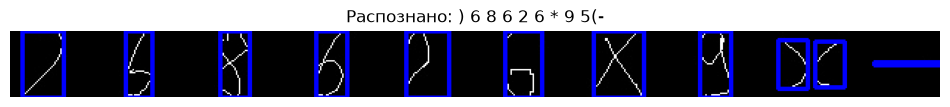

Оригинал:   y8t226(4x6
Распознано: y 8 t 2 2 6 ( 4 x 6
Точность:   100.0%


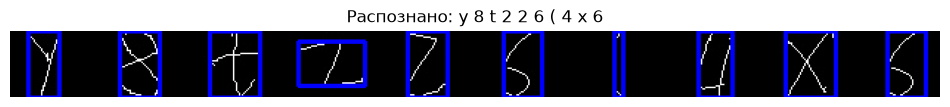

Оригинал:   )6-13474-3
Распознано: ) 6 - 1 3 4 7 4 - 3
Точность:   100.0%


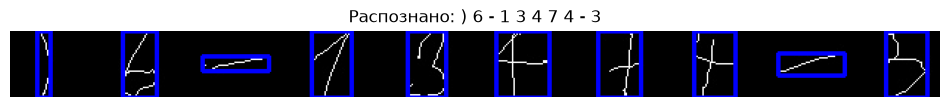

In [23]:
def recognize_sequence(sequence, images, model, visualize=True):
    line_gray = gen_image_line(images)
    line_rgb = cv2.cvtColor(line_gray, cv2.COLOR_GRAY2RGB)

    _, thresh = cv2.threshold(line_rgb, 127, 255, 0)
    contours, _ = cv2.findContours(np.uint8(thresh)[:, :, 0], cv2.RETR_EXTERNAL, 2)

    crops = []
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        if w * h > 50:
            crops.append([x, y, w, h])
    crops.sort(key=lambda c: c[0])

    predicted = ""
    prev_end = -100
    debug = line_rgb.copy()

    for (x, y, w, h) in crops:
        if prev_end != -100 and (x - prev_end) > 25:
            predicted += " "
        cv2.rectangle(debug, (x, y), (x + w, y + h), (0, 0, 255), 2)

        img = line_gray[y:y + h, x:x + w]               # black bg + white ink
        base = np.zeros((img.shape[0] + 2, img.shape[1] + 30), dtype=np.uint8)
        base[1:img.shape[0] + 1, 15:img.shape[1] + 15] = img
        padded = pad_and_crop(base)                     # black bg + white ink, 45×45
        vec = cv2.bitwise_not(padded).flatten().astype(np.float32) / 255.0
        predicted += str(model.predict([vec])[0])
        prev_end = x + w

    clean_pred = predicted.replace(" ", "")
    clean_true = sequence.replace(" ", "")
    correct = sum(1 for p, s in zip(clean_pred, clean_true) if p == s)
    accuracy = correct / len(clean_true) if clean_true else 0.0

    print(f"Оригинал:   {sequence}")
    print(f"Распознано: {predicted}")
    print(f"Точность:   {accuracy * 100:.1f}%")

    if visualize:
        plt.figure(figsize=(12, 2))
        plt.imshow(debug)
        plt.title(f"Распознано: {predicted}")
        plt.axis('off')
        plt.show()
    return predicted, accuracy


print("ТЕСТИРОВАНИЕ РАСПОЗНАВАНИЯ")
for _ in range(3):
    test_seq, test_imgs = generator.generate_sequence(length=10)
    recognize_sequence(test_seq, test_imgs, best_model)